In [16]:
import numpy as np

# Your provided dataset
data = [
    ["this is class of fovl", 0],
    ["this is class of ml", 1],
    ["this is class of cv", 1],
    ["this is class of os", 0],
    ["this is class of vl", 0],
    ["this is class of ovl", 1],
    ["this is class of pl", 1],
]


def softmax(x):
  # Subtract max for numerical stability
  e_x = np.exp(x - np.max(x))
  return e_x / np.sum(e_x)


def word2vec_skipgram(corpus, c=2, d=8, eta=0.05, T=100):
  """Implements WORD2VEC-SKIPGRAM(Corpus, c, d, η, T) from the slide.

  Parameters:
      corpus : list of strings (sentences)
      c      : context window size
      d      : embedding dimensionality
      eta    : learning rate (η)
      T      : number of epochs
  """
  # 1. Build vocabulary V from the corpus
  tokenized_sentences = [sentence.lower().split() for sentence in corpus]
  vocab = sorted(list(set(word for sent in tokenized_sentences for word in sent)))
  word2idx = {w: idx for idx, w in enumerate(vocab)}
  idx2word = {idx: w for idx, w in enumerate(vocab)}
  V = len(vocab)

  # 2. Initialize input embeddings E randomly (Shape: |V| x d)
  np.random.seed(42)
  E = np.random.uniform(-0.5, 0.5, (V, d))

  # 3. Initialize output weights W randomly (Shape: d x |V|)
  W = np.random.uniform(-0.5, 0.5, (d, V))

  # 4. Generate training pairs
  training_pairs = []
  for sentence in tokenized_sentences:
    n = len(sentence)
    for i, w in enumerate(sentence):
      center_idx = word2idx[w]
      # Context position j within window c
      for j in range(max(0, i - c), min(n, i + c + 1)):
        if i != j:
          context_idx = word2idx[sentence[j]]
          training_pairs.append((center_idx, context_idx))

  print(f"Vocabulary ({V} words): {vocab}")
  print(f"Total training pairs generated (c={c}): {len(training_pairs)}\n")

  # 5. For epoch = 1 to T:
  for epoch in range(1, T + 1):
    # Shuffle training pairs
    np.random.shuffle(training_pairs)
    total_loss = 0.0

    for center, context in training_pairs:
      print(center, context)
      # --- Forward pass ---
      h = E[center]  # Shape: (d,)
      scores = np.dot(h, W)  # h x W -> Shape: (|V|,)
      probabilities = softmax(scores)  # Softmax(scores) -> Shape: (|V|,)

      # --- Compute loss ---
      loss = -np.log(probabilities[context] + 1e-10)
      total_loss += loss

      # --- Backpropagation ---
      error = probabilities.copy()  # Shape: (|V|,)
      error[context] -= 1.0  # error[context] -= 1

      # Outer product: h^T x error -> Shape: (d, |V|)
      gradient_W = np.outer(h, error)
      # Matrix-vector product: W x error -> Shape: (d,)
      gradient_h = np.dot(W, error)

      # --- Update parameters ---
      W = W - eta * gradient_W
      E[center] = E[center] - eta * gradient_h

    if epoch % 20 == 0 or epoch == 1:
      avg_loss = total_loss / len(training_pairs)
      print(f"Epoch {epoch:3d}/{T} | Average Loss: {avg_loss:.4f}")

  # 6. Return E
  return E, word2idx, idx2word


# --- Run Skip-Gram on your data ---
corpus = [row[0] for row in data]
labels = np.array([row[1] for row in data])

E, word2idx, idx2word = word2vec_skipgram(
    corpus, c=2, d=5, eta=0.05, T=100
)

print("\nLearned Word Embeddings (E):")
for word, idx in word2idx.items():
  print(f"{word:>5s} : {np.round(E[idx], 4)}")

Streaming output truncated to the last 5000 lines.
5 10
0 9
10 0
5 3
4 5
7 0
3 0
3 0
9 0
2 0
0 6
3 9
9 3
5 3
6 0
3 5
3 9
10 5
3 5
0 5
9 3
0 3
3 9
1 5
0 10
3 5
0 5
0 5
0 1
6 5
5 3
2 5
8 5
9 3
0 5
0 3
9 0
0 9
9 0
3 9
0 5
0 5
5 0
0 3
0 4
0 3
0 3
9 3
3 5
0 9
5 3
0 3
5 3
7 5
0 9
5 7
9 0
5 3
3 0
5 0
3 5
4 0
5 6
9 0
5 2
5 0
5 4
0 9
0 3
9 0
5 0
3 5
3 9
0 5
3 9
9 0
9 3
3 0
3 0
9 3
5 3
0 8
0 2
9 3
1 0
0 1
0 5
6 0
3 9
5 3
9 0
2 0
8 5
3 9
0 3
9 3
9 3
0 5
3 0
0 9
3 5
0 9
0 9
0 5
5 0
0 3
3 0
3 9
9 0
5 0
3 5
0 3
0 8
5 0
9 3
9 0
5 0
3 5
0 9
5 3
3 5
5 3
0 5
9 0
3 0
5 3
0 5
2 5
5 0
3 9
3 5
5 3
0 3
0 3
0 5
9 0
0 6
3 0
5 7
0 7
3 9
3 9
8 0
3 9
3 0
5 0
0 3
4 5
0 9
9 0
9 3
0 4
7 5
9 3
0 5
0 9
5 3
9 3
9 0
0 3
1 5
6 5
9 3
3 0
3 0
5 0
5 6
0 9
7 0
0 2
5 8
10 5
5 4
5 1
0 10
3 5
5 2
5 3
5 10
10 0
3 5
4 0
5 3
3 9
5 0
3 9
0 5
6 0
3 5
4 5
10 5
10 0
9 0
1 5
5 3
7 0
0 5
5 3
4 0
9 3
9 0
0 5
3 0
0 4
0 3
9 3
0 9
3 0
3 9
5 0
0 9
0 3
5 3
3 9
3 5
5 8
6 5
0 8
0 7
5 10
5 6
9 3
5 4
3 9
5 3
0 3
9 3
0 3
0 9
3 5
0 3
5 3
0 5
5 0
7 

In [4]:
# Tokenize the corpus
tokenized_sentences = [sentence.lower().split() for sentence in corpus]

# Set the context window size
c = 2
training_pairs = []

# Generate training pairs (center_word, context_word)
for sentence in tokenized_sentences:
    n = len(sentence)
    for i, w in enumerate(sentence):
        # Context position j within window c
        for j in range(max(0, i - c), min(n, i + c + 1)):
            if i != j:
                training_pairs.append((w, sentence[j]))

# Display some of the generated pairs
print(f"Total training pairs generated (c={c}): {len(training_pairs)}")
print("First 15 training pairs (Center -> Context):")
for center, context in training_pairs[:15]:
    print(f"  {center:5s} -> {context}")

Total training pairs generated (c=2): 98
First 15 training pairs (Center -> Context):
  this  -> is
  this  -> class
  is    -> this
  is    -> class
  is    -> of
  class -> this
  class -> is
  class -> of
  class -> fovl
  of    -> is
  of    -> class
  of    -> fovl
  fovl  -> class
  fovl  -> of
  this  -> is


In [10]:
# Build the vocabulary of unique words
vocabulary = {}
word_set = set()

# Fix: use the correct variable name 'data'
for sentence, label in data:
    words = sentence.lower().split()
    for word in words:
        word_set.add(word)

# Map each unique word to a unique integer ID
vocabulary = {word: index for index, word in enumerate(sorted(word_set))}

print("Vocabulary size:", len(vocabulary))
print("Vocabulary:")
for word, index in vocabulary.items():
    print(f"'{word}': {index}")

Vocabulary size: 11
Vocabulary:
'class': 0
'cv': 1
'fovl': 2
'is': 3
'ml': 4
'of': 5
'os': 6
'ovl': 7
'pl': 8
'this': 9
'vl': 10


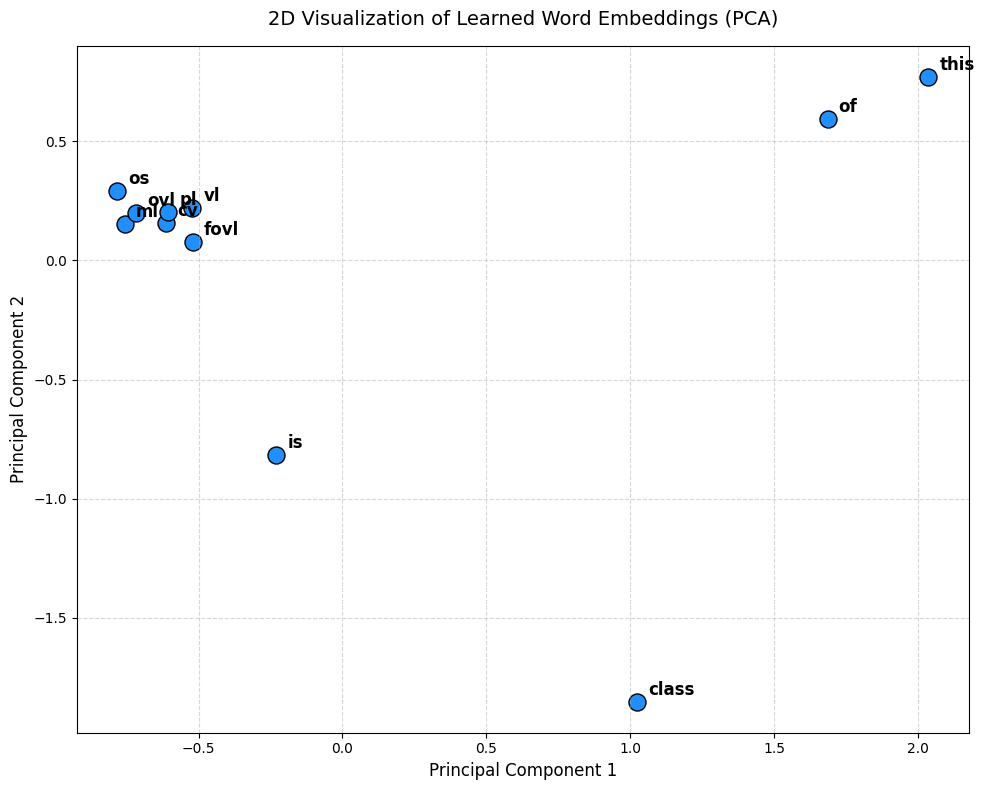

In [8]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# Prepare the embedding matrix and labels
words = list(word2idx.keys())
embedding_matrix = np.array([E[word2idx[w]] for w in words])

# Perform PCA to reduce dimensionality to 2D
pca = PCA(n_components=2)
coords = pca.fit_transform(embedding_matrix)

# Create the plot
plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1], color='dodgerblue', edgecolors='k', s=150)

# Annotate the points with their corresponding words
for i, word in enumerate(words):
    plt.annotate(word, (coords[i, 0], coords[i, 1]), xytext=(8, 5), textcoords='offset points', fontsize=12, weight='bold')

plt.title("2D Visualization of Learned Word Embeddings (PCA)", fontsize=14, pad=15)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
word2idx

{'class': 0,
 'cv': 1,
 'fovl': 2,
 'is': 3,
 'ml': 4,
 'of': 5,
 'os': 6,
 'ovl': 7,
 'pl': 8,
 'this': 9,
 'vl': 10}

In [13]:
# Vectorize the tokenized data
vectors = []
vocab_size = len(vocabulary)

# Fix: iterate over 'data' and tokenize each sentence on the fly
for sentence, label in data:
    words = sentence.lower().split()
    # Initialize a zero vector for the sentence
    vector = [0] * vocab_size
    for word in words:
        if word in vocabulary:
            vector[vocabulary[word]] = 1
    vectors.append([vector, label])

# Display the resulting vectors
for vector, label in vectors:
    print(f"Vector: {vector} -> Label: {label}")

Vector: [1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0] -> Label: 0
Vector: [1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0] -> Label: 1
Vector: [1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0] -> Label: 1
Vector: [1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0] -> Label: 0
Vector: [1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1] -> Label: 0
Vector: [1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0] -> Label: 1
Vector: [1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0] -> Label: 1


In [14]:
training_pairs


[('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'fovl'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'fovl'),
 ('fovl', 'class'),
 ('fovl', 'of'),
 ('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'ml'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'ml'),
 ('ml', 'class'),
 ('ml', 'of'),
 ('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'cv'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'cv'),
 ('cv', 'class'),
 ('cv', 'of'),
 ('this', 'is'),
 ('this', 'class'),
 ('is', 'this'),
 ('is', 'class'),
 ('is', 'of'),
 ('class', 'this'),
 ('class', 'is'),
 ('class', 'of'),
 ('class', 'os'),
 ('of', 'is'),
 ('of', 'class'),
 ('of', 'os'),
 ('os', 'class'),
 ('os', 'of'),
 ('this', 'is'),
 ('this

In [17]:
import numpy as np

# Let's demonstrate how Cross-Entropy Loss works in your Skip-Gram model
# Suppose our vocabulary size is 11, and the true context word is at index 2 ('fovl')
true_context_idx = 2

# 1. Create a true one-hot encoded vector (y_true)
y_true = np.zeros(11)
y_true[true_context_idx] = 1.0

# 2. Dummy predicted probabilities from the softmax layer (y_pred)
# (Assuming the model predicts 'fovl' with 60% probability)
y_pred = np.array([0.05, 0.05, 0.60, 0.05, 0.05, 0.05, 0.05, 0.05, 0.02, 0.03, 0.05])

# Add a small epsilon to prevent calculating log(0) which is undefined
epsilon = 1e-10

# Standard categorical cross entropy formula: - sum(y_true * log(y_pred))
cross_entropy_loss = -np.sum(y_true * np.log(y_pred + epsilon))

# Simplified formula for one-hot vectors (This is exactly what you used in your training loop!)
simplified_loss = -np.log(y_pred[true_context_idx] + epsilon)

print(f"True one-hot vector (y_true):\n{y_true}\n")
print(f"Predicted probabilities (y_pred):\n{y_pred}\n")
print(f"Standard Cross-Entropy Loss:\t\t {cross_entropy_loss:.4f}")
print(f"Simplified Loss (used in your code):\t {simplified_loss:.4f}")
print("\nAs you can see, they are mathematically identical!")

True one-hot vector (y_true):
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]

Predicted probabilities (y_pred):
[0.05 0.05 0.6  0.05 0.05 0.05 0.05 0.05 0.02 0.03 0.05]

Standard Cross-Entropy Loss:		 0.5108
Simplified Loss (used in your code):	 0.5108

As you can see, they are mathematically identical!
